In [48]:
%pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [49]:
# Cell 1: Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [50]:
# Cell 51: Summarize charging sessions per user
valid_users = df[
    df["User ID"].notna() &
    (df["User ID"].astype(str).str.strip() != "0")
].copy()

# Count charging sessions per user
sessions_per_user = valid_users["User ID"].value_counts()

print("Number of unique users:", len(sessions_per_user))
print("Average sessions per user:", round(sessions_per_user.mean(), 2))
print("Median sessions per user:", sessions_per_user.median())

print("Users with only 1 session:",
      (sessions_per_user == 1).sum())

print("Users with at least 10 sessions:",
      (sessions_per_user >= 10).sum())

display(sessions_per_user.describe())


Number of unique users: 21433
Average sessions per user: 11.7
Median sessions per user: 2.0
Users with only 1 session: 9369
Users with at least 10 sessions: 3605


count    21433.000000
mean        11.703961
std         44.639893
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max       1113.000000
Name: count, dtype: float64

In [51]:
# Load the cleaned dataset
df = pd.read_csv("/Users/juliakuras/Downloads/EVChargingStationUsage_cleaned.csv", low_memory=False)

df["Start Date"] = pd.to_datetime(df["Start Date"], format="ISO8601")
df["End Date"] = pd.to_datetime(df["End Date"], format="ISO8601")

print(df.shape)
print("Missing end dates:", df["End Date"].isna().sum()) 

(258950, 36)
Missing end dates: 0


In [52]:
# calculate when charging stopped
# sssumption: charging starts immediately at plug-in,
# so charging stops at plug-in time + charging time
df["Charging End"] = df["Start Date"] + pd.to_timedelta(df["Charging Time Hours"], unit="h").dt.round("s")

df["Charging End"] = df[["Charging End", "End Date"]].min(axis=1)

df[["Start Date", "End Date", "Charging Time Hours", "Charging End"]].head(10)

,Start Date,End Date,Charging Time Hours,Charging End
0,2011-07-29 20:17:00,2011-07-29 23:20:00,1.900833,2011-07-29 22:11:03
1,2011-07-30 00:00:00,2011-07-30 00:02:00,0.031667,2011-07-30 00:01:54
2,2011-07-30 08:16:00,2011-07-30 12:34:00,4.291111,2011-07-30 12:33:28
3,2011-07-30 14:51:00,2011-07-30 16:55:00,2.049444,2011-07-30 16:53:58
4,2011-07-30 18:51:00,2011-07-30 20:03:00,0.731667,2011-07-30 19:34:54
5,2011-07-30 21:38:00,2011-07-31 01:30:00,1.516111,2011-07-30 23:08:58
6,2011-07-31 04:33:00,2011-07-31 10:40:00,4.946389,2011-07-31 09:29:47
7,2011-07-31 12:25:00,2011-07-31 13:35:00,1.163611,2011-07-31 13:34:49
8,2011-07-31 17:41:00,2011-07-31 22:31:00,4.687778,2011-07-31 22:22:16
9,2011-08-01 19:11:00,2011-08-01 22:34:00,1.585556,2011-08-01 20:46:08


In [53]:
ONE_HOUR = pd.Timedelta(hours=1)

example = df.iloc[0]
plug_in, unplug = example["Start Date"], example["End Date"]
charge_end, energy = example["Charging End"], example["Energy (kWh)"]
charging_hours = (charge_end - plug_in) / ONE_HOUR

print(f"Session: plugged in {plug_in}, charging ended {charge_end}, unplugged {unplug}, {energy} kWh\n")

hour = plug_in.floor("h")
while hour < unplug:
    next_hour = hour + ONE_HOUR
    plugged = (min(unplug, next_hour) - max(plug_in, hour)) / ONE_HOUR
    charging = max((min(charge_end, next_hour) - max(plug_in, hour)) / ONE_HOUR, 0)
    print(f"{hour.strftime('%H:%M')}-{next_hour.strftime('%H:%M')}: "
          f"plugged in {plugged:.2f} h, charging {charging:.2f} h, "
          f"energy {energy * charging / charging_hours:.2f} kWh")
    hour = next_hour

Session: plugged in 2011-07-29 20:17:00, charging ended 2011-07-29 22:11:03, unplugged 2011-07-29 23:20:00, 6.249457 kWh

20:00-21:00: plugged in 0.72 h, charging 0.72 h, energy 2.36 kWh
21:00-22:00: plugged in 1.00 h, charging 1.00 h, energy 3.29 kWh
22:00-23:00: plugged in 1.00 h, charging 0.18 h, energy 0.61 kWh
23:00-00:00: plugged in 0.33 h, charging 0.00 h, energy 0.00 kWh


In [54]:
print("Sessions with zero charging time:", (df["Charging End"] == df["Start Date"]).sum())

Sessions with zero charging time: 1


In [55]:
zero_charging = df["Charging End"] == df["Start Date"]
print("Sessions removed (zero charging time):", zero_charging.sum())

Sessions removed (zero charging time): 1


In [56]:
df = df[~zero_charging].copy()
print("Remaining sessions:", len(df))

Remaining sessions: 258949


In [57]:
# split ALL charging sessions into the clock hours they cover
# (same logic as the single-session demo above, applied to every session)

pieces = []

# go through the sessions one at a time; zip hands over one session's values per round
for station, user, plug_in, unplug, charge_end, energy in zip(
        df["Station Name"], df["User ID"], df["Start Date"],
        df["End Date"], df["Charging End"], df["Energy (kWh)"]):

    charging_hours = (charge_end - plug_in) / ONE_HOUR

    hour = plug_in.floor("h")

    while hour < unplug:
        next_hour = hour + ONE_HOUR

        plugged = (min(unplug, next_hour) - max(plug_in, hour)) / ONE_HOUR

        charging = max((min(charge_end, next_hour) - max(plug_in, hour)) / ONE_HOUR, 0)

        energy_this_hour = energy * charging / charging_hours

        pieces.append((station, user, hour, energy_this_hour, plugged))

        hour = next_hour

print("Done. Number of pieces:", len(pieces))

Done. Number of pieces: 897268


In [58]:
for piece in pieces[:5]:
    print(piece)

('PALO ALTO CA / HAMILTON #1', '3284', Timestamp('2011-07-29 20:00:00'), 2.3562178956597983, 0.7166666666666667)
('PALO ALTO CA / HAMILTON #1', '3284', Timestamp('2011-07-29 21:00:00'), 3.2877459009206484, 1.0)
('PALO ALTO CA / HAMILTON #1', '3284', Timestamp('2011-07-29 22:00:00'), 0.6054932034195527, 1.0)
('PALO ALTO CA / HAMILTON #1', '3284', Timestamp('2011-07-29 23:00:00'), 0.0, 0.3333333333333333)
('PALO ALTO CA / HAMILTON #1', '4169', Timestamp('2011-07-30 00:00:00'), 0.106588, 0.03333333333333333)


In [59]:
hourly = pd.DataFrame(pieces, columns=[
    "Station Name", "User ID", "Hour", "Energy (kWh)", "Occupied Hours"
])

print("Charging sessions:", len(df))
print("Hourly pieces:", len(hourly))
hourly.head(10)

Charging sessions: 258949
Hourly pieces: 897268


,Station Name,User ID,Hour,Energy (kWh),Occupied Hours
0,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 20:00:00,2.356218,0.716667
1,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 21:00:00,3.287746,1.000000
2,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 22:00:00,0.605493,1.000000
3,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 23:00:00,0.000000,0.333333
4,PALO ALTO CA / HAMILTON #1,4169,2011-07-30 00:00:00,0.106588,0.033333
5,PALO ALTO CA / HAMILTON #1,4169,2011-07-30 08:00:00,2.555198,0.733333
6,PALO ALTO CA / HAMILTON #1,4169,2011-07-30 09:00:00,3.484360,1.000000
7,PALO ALTO CA / HAMILTON #1,4169,2011-07-30 10:00:00,3.484360,1.000000
8,PALO ALTO CA / HAMILTON #1,4169,2011-07-30 11:00:00,3.484360,1.000000
9,PALO ALTO CA / HAMILTON #1,4169,2011-07-30 12:00:00,1.943499,0.566667


In [60]:
# check that nothing was lost in the split
# the total energy and total plugged-in time must be the same before and after.

plugged_before = ((df["End Date"] - df["Start Date"]) / ONE_HOUR).sum()

print("Total energy (kWh)     before:", round(df["Energy (kWh)"].sum(), 1),
      "| after:", round(hourly["Energy (kWh)"].sum(), 1))
print("Total plugged-in hours before:", round(plugged_before, 1),
      "| after:", round(hourly["Occupied Hours"].sum(), 1))

Total energy (kWh)     before: 2211609.1 | after: 2211609.1
Total plugged-in hours before: 642232.0 | after: 642232.0


In [61]:
# how many sessions have no valid user?
invalid = df["User ID"].isna() | (df["User ID"].astype(str) == "0")

print("Invalid sessions:", invalid.sum())

df[invalid].head(10)

Invalid sessions: 8098


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number,Total Duration Hours,Charging Time Hours,Idle Time Hours,Charging End
10,PALO ALTO CA / HAMILTON #2,000D:6F00:009E:D39E,City of Palo Alto,2011-08-02 12:26:00,PDT,2011-08-02 13:27:00,PDT,8/2/2011 13:27,1:00:50,1:00:43,...,8,NaN,0,NaN,NaN,NaN,1.013889,1.011944,0.001944,2011-08-02 13:26:43
21,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-08-04 20:13:00,PDT,2011-08-04 23:11:00,PDT,8/4/2011 23:11,2:58:33,2:57:27,...,19,NaN,0,NaN,NaN,NaN,2.975833,2.957500,0.018333,2011-08-04 23:10:27
38,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-08-08 16:27:00,PDT,2011-08-08 18:11:00,PDT,8/8/2011 18:11,1:43:24,1:43:18,...,1312846070,NaN,0,NaN,NaN,NaN,1.723333,1.721667,0.001667,2011-08-08 18:10:18
116,PALO ALTO CA / HAMILTON #2,000D:6F00:009E:D39E,City of Palo Alto,2011-08-27 13:42:00,PDT,2011-08-27 15:36:00,PDT,8/27/2011 15:36,1:53:25,1:53:13,...,1314477764,NaN,0,NaN,NaN,NaN,1.890278,1.886944,0.003333,2011-08-27 15:35:13
120,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-08-28 10:36:00,PDT,2011-08-28 12:29:00,PDT,8/28/2011 12:29,1:52:19,1:51:49,...,76,NaN,0,NaN,NaN,NaN,1.871944,1.863611,0.008333,2011-08-28 12:27:49
126,PALO ALTO CA / HAMILTON #2,000D:6F00:009E:D39E,City of Palo Alto,2011-08-29 11:26:00,PDT,2011-08-29 13:17:00,PDT,8/29/2011 13:17,1:50:41,1:50:34,...,1314642412,NaN,0,NaN,NaN,NaN,1.844722,1.842778,0.001944,2011-08-29 13:16:34
136,PALO ALTO CA / HAMILTON #2,000D:6F00:009E:D39E,City of Palo Alto,2011-08-31 13:01:00,PDT,2011-08-31 14:03:00,PDT,8/31/2011 14:03,1:02:02,1:00:57,...,87,NaN,0,NaN,NaN,NaN,1.033889,1.015833,0.018056,2011-08-31 14:01:57
138,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-08-31 15:22:00,PDT,2011-08-31 16:52:00,PDT,8/31/2011 16:52,1:30:03,1:29:54,...,1314829331,NaN,0,NaN,NaN,NaN,1.500833,1.498333,0.002500,2011-08-31 16:51:54
167,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-09-06 08:52:00,PDT,2011-09-06 10:49:00,PDT,9/6/2011 10:49,1:56:58,1:56:33,...,104,NaN,0,NaN,NaN,NaN,1.949444,1.942500,0.006944,2011-09-06 10:48:33
170,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-09-06 13:24:00,PDT,2011-09-06 15:25:00,PDT,9/6/2011 15:25,2:01:54,2:01:50,...,106,NaN,0,NaN,NaN,NaN,2.031667,2.030556,0.001111,2011-09-06 15:25:00


In [62]:
df = df[~invalid].copy()

print(df.shape)

(250851, 37)


In [63]:
# hourly energy use and charger occupation per USER (TASK 1)

# keep only pieces with a valid user: remove missing IDs and the placeholder "0"
hourly_users = hourly[
    hourly["User ID"].notna() &
    (hourly["User ID"].astype(str).str.strip() != "0")
]

# add up all pieces per user and hour
# (if a user charged twice in the same hour, the two pieces become one row)
user_hourly = (
    hourly_users.groupby(["User ID", "Hour"])[["Energy (kWh)", "Occupied Hours"]]
    .sum()
    .reset_index()
)

print("Users:", user_hourly["User ID"].nunique())
print("User-hour rows:", len(user_hourly))
user_hourly.head(10)

Users: 21433
User-hour rows: 858330


,User ID,Hour,Energy (kWh),Occupied Hours
0,1000031,2019-06-04 18:00:00,1.453244,0.516667
1,1000031,2019-06-04 19:00:00,2.812730,1.000000
2,1000031,2019-06-04 20:00:00,0.693026,1.000000
3,1000031,2019-06-04 21:00:00,0.000000,1.000000
4,1000031,2019-06-04 22:00:00,0.000000,0.100000
5,1000311,2019-05-24 19:00:00,3.730556,0.666667
6,1000311,2019-05-24 20:00:00,5.595833,1.000000
7,1000311,2019-05-24 21:00:00,4.103611,0.733333
8,100061V,2019-11-05 08:00:00,2.189029,0.366667
9,100061V,2019-11-05 09:00:00,5.970080,1.000000


In [64]:
# Step 4a: Add time information to every user-hour row

# Hour of Day: 0-23, taken from the hour timestamp
user_hourly["Hour of Day"] = user_hourly["Hour"].dt.hour

# Weekend: True for Saturday (5) and Sunday (6), since Monday = 0
user_hourly["Weekend"] = user_hourly["Hour"].dt.day_of_week >= 5

# Time Block: group the 24 hours into 4 parts of the day
def time_block(hour):
    if hour < 6:
        return "Night"        # 00:00-05:59
    elif hour < 12:
        return "Morning"      # 06:00-11:59
    elif hour < 18:
        return "Afternoon"    # 12:00-17:59
    else:
        return "Evening"      # 18:00-23:59

user_hourly["Time Block"] = user_hourly["Hour of Day"].apply(time_block)

user_hourly.head()

,User ID,Hour,Energy (kWh),Occupied Hours,Hour of Day,Weekend,Time Block
0,1000031,2019-06-04 18:00:00,1.453244,0.516667,18,False,Evening
1,1000031,2019-06-04 19:00:00,2.812730,1.000000,19,False,Evening
2,1000031,2019-06-04 20:00:00,0.693026,1.000000,20,False,Evening
3,1000031,2019-06-04 21:00:00,0.000000,1.000000,21,False,Evening
4,1000031,2019-06-04 22:00:00,0.000000,0.100000,22,False,Evening


In [65]:
# total energy (kWh) per user in each time block 
block_energy = user_hourly.pivot_table(
    index="User ID",          # one row per user
    columns="Time Block",     # one column per part of the day
    values="Energy (kWh)",    # what to add up
    aggfunc="sum",            # add up the energy
    fill_value=0              # 0 if the user never charged in that block
)

block_energy = block_energy[["Night", "Morning", "Afternoon", "Evening"]]

# total energy and weekend energy per user
block_energy["Total"] = block_energy.sum(axis=1)
block_energy["Weekend"] = (
    user_hourly[user_hourly["Weekend"]]
    .groupby("User ID")["Energy (kWh)"].sum()
)
block_energy["Weekend"] = block_energy["Weekend"].fillna(0)

block_energy.round(3).head(10)

Time Block,Night,Morning,Afternoon,Evening,Total,Weekend
User ID,,,,,,
1000031,0.0,0.000,0.000,4.959,4.959,0.000
1000311,0.0,0.000,0.000,13.430,13.430,0.000
100061V,0.0,34.569,0.000,0.000,34.569,0.000
10013,0.0,0.000,3.971,7.206,11.177,0.000
100161V,0.0,25.080,8.744,0.000,33.824,0.000
1001801,0.0,9.348,0.000,0.000,9.348,0.000
1001861,0.0,0.000,0.000,5.388,5.388,0.000
1001941,0.0,0.000,2.398,0.000,2.398,2.398
1002211,0.0,4.463,20.634,0.000,25.097,25.097


In [66]:
# kWh into % of each users total energy
user_shares = block_energy[["Night", "Morning", "Afternoon", "Evening", "Weekend"]].div(block_energy["Total"], axis=0) * 100

user_shares.round(2).head(10)

Time Block,Night,Morning,Afternoon,Evening,Weekend
User ID,,,,,
1000031,0.0,0.00,0.00,100.00,0.0
1000311,0.0,0.00,0.00,100.00,0.0
100061V,0.0,100.00,0.00,0.00,0.0
10013,0.0,0.00,35.53,64.47,0.0
100161V,0.0,74.15,25.85,0.00,0.0
1001801,0.0,100.00,0.00,0.00,0.0
1001861,0.0,0.00,0.00,100.00,0.0
1001941,0.0,0.00,100.00,0.00,100.0
1002211,0.0,17.78,82.22,0.00,100.0


In [79]:
# share of users whose energy falls entirely in ONE time block
blocks = ["Night", "Morning", "Afternoon", "Evening"]
one_block = (user_shares[blocks] == 100).any(axis=1)

for minimum in [1, 3, 5, 10]:
    keep = user_shares["Sessions"] >= minimum
    print(f"At least {minimum} sessions: {one_block[keep].mean() * 100:.0f}% of users are 100% in one block")

At least 1 sessions: 3% of users are 100% in one block
At least 3 sessions: 3% of users are 100% in one block
At least 5 sessions: 2% of users are 100% in one block
At least 10 sessions: 1% of users are 100% in one block


In [69]:
# number of sessions per user (from the sessions table df)
sessions_per_user = df.groupby("User ID").size()

# add it to the shares table
user_shares["Sessions"] = sessions_per_user

# how many users would remain with different minimum thresholds?
for minimum in [1, 3, 4, 5, 6, 7, 10, 20]:
        print(f"At least {minimum} sessions:", (user_shares["Sessions"] >= minimum).sum(), "users")

At least 1 sessions: 21433 users
At least 3 sessions: 8795 users
At least 4 sessions: 7074 users
At least 5 sessions: 5971 users
At least 6 sessions: 5202 users
At least 7 sessions: 4684 users
At least 10 sessions: 3605 users
At least 20 sessions: 2212 users


In [70]:
# only users with at least 4 sessions
MIN_SESSIONS = 4
user_shares = user_shares[user_shares["Sessions"] >= MIN_SESSIONS]

# what share of all sessions do these users represent?
covered = user_shares["Sessions"].sum() / len(df) * 100

print("Users kept:", len(user_shares))
print(f"These users account for {covered:.1f}% of all sessions")

Users kept: 7074
These users account for 91.6% of all sessions


In [71]:
# average energy per session and average idle time per user (from the sessions table df)
user_stats = df.groupby("User ID").agg(
    Avg_Energy=("Energy (kWh)", "mean"),       # average kWh per session
    Avg_Idle_Hours=("Idle Time Hours", "mean")  # average time plugged in after charging finished
)

# Add both columns to the shares table (matched by User ID)
user_shares = user_shares.join(user_stats)

user_shares.round(2).head(10)

,Night,Morning,Afternoon,Evening,Weekend,Sessions,Avg_Energy,Avg_Idle_Hours
User ID,,,,,,,,
100161V,0.00,74.15,25.85,0.00,0.00,4,8.46,0.23
100243,9.33,7.91,22.05,60.71,26.95,649,8.20,2.58
100293,0.00,59.32,3.89,36.79,61.34,15,6.41,1.15
100393,0.00,0.00,41.41,58.59,13.02,9,1.32,0.18
1004021,18.14,81.86,0.00,0.00,0.00,5,3.56,0.01
100523,0.00,12.40,77.02,10.58,8.10,41,7.70,0.23
1007181,0.00,15.28,84.72,0.00,45.93,7,2.59,0.08
1007531,0.00,0.00,14.97,85.03,14.97,4,10.19,0.00
100803,23.09,15.38,23.21,38.32,13.86,56,6.85,1.35


In [72]:
from sklearn.preprocessing import StandardScaler

# columns used for clustering
feature_cols = ["Night", "Morning", "Afternoon", "Evening", "Weekend",
                "Avg_Energy", "Avg_Idle_Hours"]

X = user_shares[feature_cols]

# check for missing values before scaling (should all be 0)
print(X.isna().sum())

# standardize: (value - mean) / standard deviation, for each column
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# look at the result: every column should now have mean ≈ 0 and std ≈ 1
pd.DataFrame(X_scaled, columns=feature_cols).describe().round(2)

Night             0
Morning           0
Afternoon         0
Evening           0
Weekend           0
Avg_Energy        0
Avg_Idle_Hours    0
dtype: int64


,Night,Morning,Afternoon,Evening,Weekend,Avg_Energy,Avg_Idle_Hours
count,7074.00,7074.00,7074.00,7074.00,7074.00,7074.00,7074.00
mean,-0.00,0.00,-0.00,0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.22,-0.88,-1.78,-1.10,-1.04,-1.47,-0.55
25%,-0.22,-0.84,-0.79,-0.95,-1.02,-0.63,-0.52
50%,-0.22,-0.35,-0.03,-0.21,-0.21,-0.23,-0.32
75%,-0.22,0.48,0.74,0.73,0.68,0.34,0.10
max,14.04,3.27,2.12,2.37,2.31,10.70,18.00


In [73]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)   # try K = 2, 3, ..., 10
inertias = []             # distortion for each K (for the elbow curve)
silhouettes = []          # silhouette score for each K

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)                          # within-cluster distance
    silhouettes.append(silhouette_score(X_scaled, labels))    # cluster separation

    print(f"K = {k}: inertia = {kmeans.inertia_:.0f}, silhouette = {silhouettes[-1]:.3f}")

K = 2: inertia = 40040, silhouette = 0.239
K = 3: inertia = 32381, silhouette = 0.238
K = 4: inertia = 26365, silhouette = 0.264
K = 5: inertia = 23193, silhouette = 0.257
K = 6: inertia = 21220, silhouette = 0.263
K = 7: inertia = 19433, silhouette = 0.264
K = 8: inertia = 18141, silhouette = 0.234
K = 9: inertia = 16901, silhouette = 0.237
K = 10: inertia = 16032, silhouette = 0.231


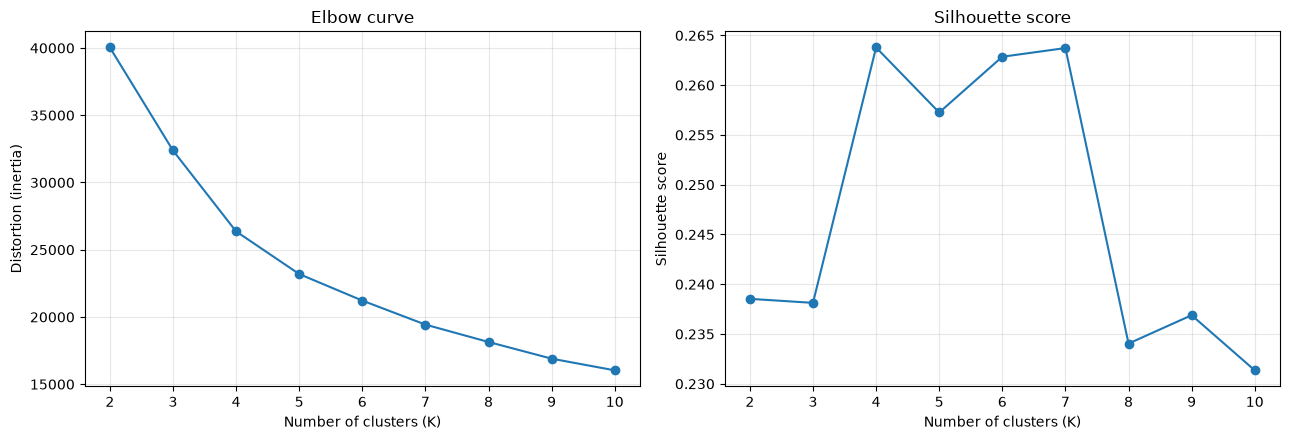

In [74]:
# the elbow curve and silhouette scores side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Distortion (inertia)")
axes[0].set_title("Elbow curve")
axes[0].grid(alpha=0.3)

axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [75]:
# final K-means model with the chosen K
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)

user_shares["Cluster"] = kmeans.fit_predict(X_scaled)

print(user_shares["Cluster"].value_counts().sort_index())

Cluster
0    1524
1    2428
2    2891
3     231
Name: count, dtype: int64


In [76]:
# average profile of each cluster, in real units
cluster_profile = user_shares.groupby("Cluster")[feature_cols + ["Sessions"]].mean()
cluster_profile["Users"] = user_shares["Cluster"].value_counts().sort_index()

cluster_profile.round(1)

,Night,Morning,Afternoon,Evening,Weekend,Avg_Energy,Avg_Idle_Hours,Sessions,Users
Cluster,,,,,,,,,
0,0.4,59.6,32.6,7.4,21.4,8.8,0.4,53.9,1524
1,0.7,7.0,27.2,65.1,34.6,6.8,0.3,20.1,2428
2,0.1,13.6,70.3,15.9,33.2,7.1,0.2,28.2,2891
3,28.2,12.6,18.0,41.2,33.8,17.9,2.0,74.7,231


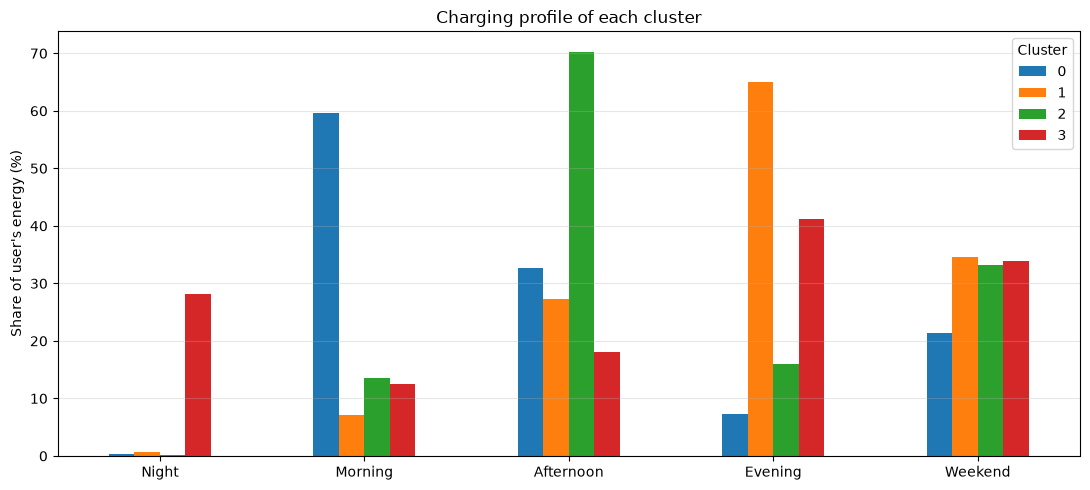

In [77]:
# compare when each cluster charges (time-of-day shares + weekend share)
plot_cols = ["Night", "Morning", "Afternoon", "Evening", "Weekend"]

cluster_profile[plot_cols].T.plot(kind="bar", figsize=(11, 5))

plt.ylabel("Share of user's energy (%)")
plt.title("Charging profile of each cluster")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

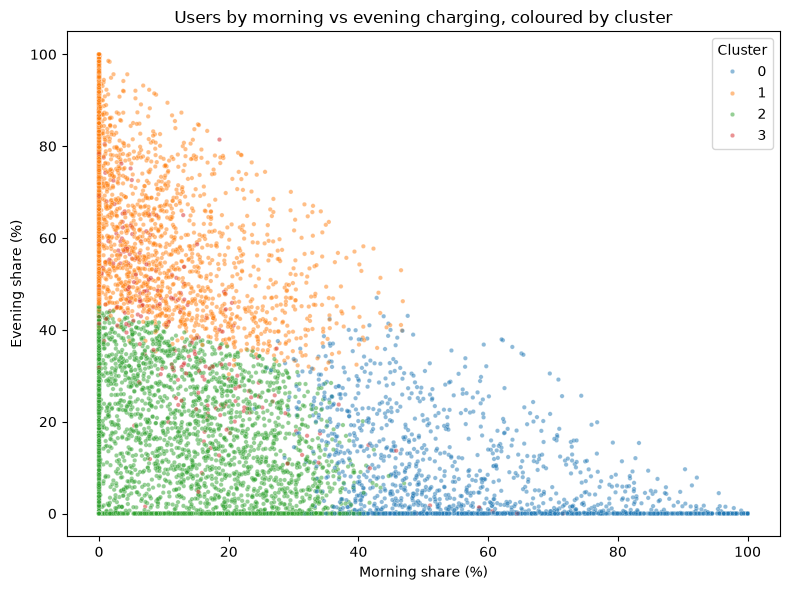

In [78]:
# each dot is one user; position = their morning vs evening share; colour = their cluster
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=user_shares,
    x="Morning", y="Evening",
    hue="Cluster", palette="tab10",
    s=10, alpha=0.5
)

plt.xlabel("Morning share (%)")
plt.ylabel("Evening share (%)")
plt.title("Users by morning vs evening charging, coloured by cluster")
plt.tight_layout()
plt.show()